# Введение

План проекта DeepLoc 2.0

1. EDA — исследование данных
   Проверили распределение классов, количество меток, размеры фолдов. Осталось изучить последовательности.

2. Preprocessing — подготовка последовательностей
   Проверить длины белков, допустимые аминокислоты, пропуски, дубликаты. Подготовить последовательности для ML.
   
3. Baseline — первая ML-модель
   Использовать TF-IDF с символьными n-граммами и Logistic Regression. Это будет модель, с которой сравниваем последующие подходы.
   
4. Model evaluation — оценка качества
   Macro F1, Micro F1, Precision, Recall, PR-AUC. Проверить качество отдельно для каждой локализации.

# Подготовка библиотек

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

pd.set_option("display.max_rows", None)

# EDA

In [2]:
df = pd.read_csv('data/raw/Swissprot_Train_Validation_dataset.csv')

print("Shape:", df.shape)
df.info()
df.head()

Shape: (28303, 16)
<class 'pandas.DataFrame'>
RangeIndex: 28303 entries, 0 to 28302
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             28303 non-null  int64  
 1   ACC                    28303 non-null  str    
 2   Kingdom                28303 non-null  str    
 3   Partition              28303 non-null  int64  
 4   Membrane               28303 non-null  float64
 5   Cytoplasm              28303 non-null  float64
 6   Nucleus                28303 non-null  float64
 7   Extracellular          28303 non-null  float64
 8   Cell membrane          28303 non-null  float64
 9   Mitochondrion          28303 non-null  float64
 10  Plastid                28303 non-null  float64
 11  Endoplasmic reticulum  28303 non-null  float64
 12  Lysosome/Vacuole       28303 non-null  float64
 13  Golgi apparatus        28303 non-null  float64
 14  Peroxisome             28303 non-null  float64

,Unnamed: 0,ACC,Kingdom,Partition,Membrane,Cytoplasm,Nucleus,Extracellular,Cell membrane,Mitochondrion,Plastid,Endoplasmic reticulum,Lysosome/Vacuole,Golgi apparatus,Peroxisome,Sequence
0,0,Q28165,Metazoa,4,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...
1,1,Q86U42,Metazoa,4,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...
2,2,Q0GA42,Metazoa,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAALGVRLRDCCSRGAVLLLFFSLSPRPPAAAAWLLGLR...
3,3,P82349,Metazoa,1,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAATEQQGSNGPVKKSMREKAVERRNVNKEHNSNFKAGY...
4,4,Q7L5N1,Metazoa,1,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAATNGTGGSSGMEVDAAVVPSVMACGVTGSVSVALHPL...


In [3]:

for column in df.columns:
    print(column, df[column].nunique())


Unnamed: 0 28303
ACC 28303
Kingdom 4
Partition 5
Membrane 2
Cytoplasm 2
Nucleus 2
Extracellular 2
Cell membrane 2
Mitochondrion 2
Plastid 2
Endoplasmic reticulum 2
Lysosome/Vacuole 2
Golgi apparatus 2
Peroxisome 2
Sequence 28303


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
target_columns = [
    "Cell membrane",
    "Cytoplasm",
    "Endoplasmic reticulum",
    "Extracellular",
    "Golgi apparatus",
    "Lysosome/Vacuole",
    "Mitochondrion",
    "Nucleus",
    "Peroxisome",
    "Plastid"
]

sequence_column = "Sequence"


In [6]:
X = df[sequence_column]
y = df[target_columns]

print("Sequences:", X.shape)
print("Targets:", y.shape)

Sequences: (28303,)
Targets: (28303, 10)


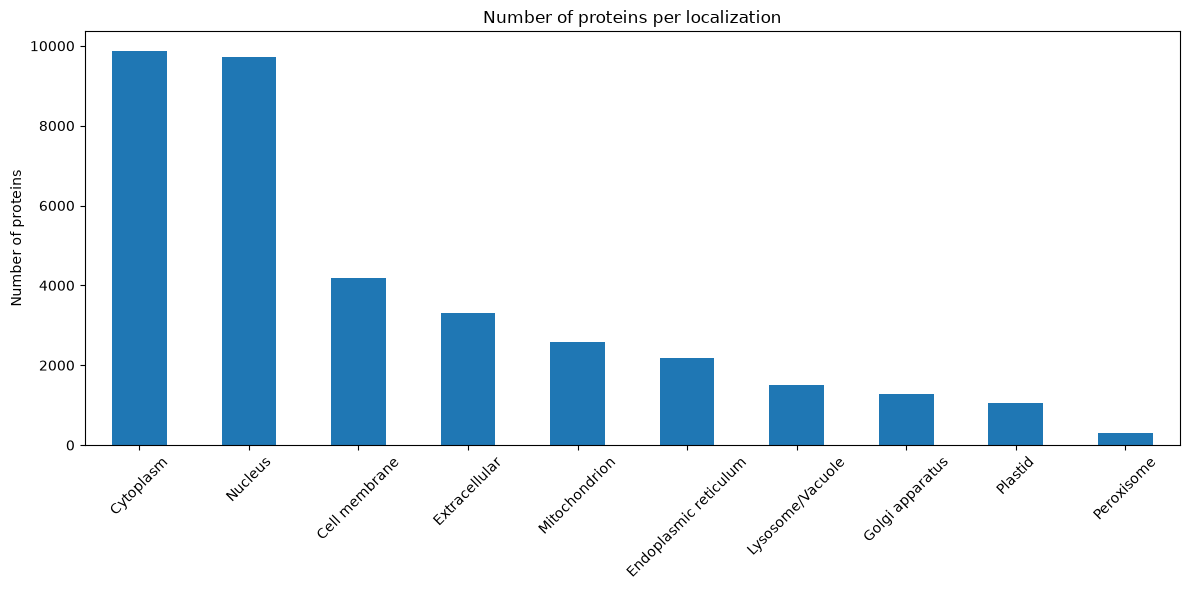

Cytoplasm                9870.0
Nucleus                  9720.0
Cell membrane            4187.0
Extracellular            3301.0
Mitochondrion            2590.0
Endoplasmic reticulum    2180.0
Lysosome/Vacuole         1496.0
Golgi apparatus          1279.0
Plastid                  1047.0
Peroxisome                304.0
dtype: float64

In [7]:

label_counts = y.sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
label_counts.plot(kind="bar")

plt.title("Number of proteins per localization")
plt.ylabel("Number of proteins")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()
display(label_counts)

**Для меток Cytoplasm и Nucleus данных сильно больше (9870 и 9720) чем для Plastid и Peroxisome (1047 и 304), что может затруднить дальнейшее обучение на редких классах и привести к различиям для предсказания разных классов.**

In [8]:
labels_per_protein = y.sum(axis=1)

print(labels_per_protein.value_counts().sort_index())

1.0    21619
2.0     5868
3.0      672
4.0      117
5.0       27
Name: count, dtype: int64


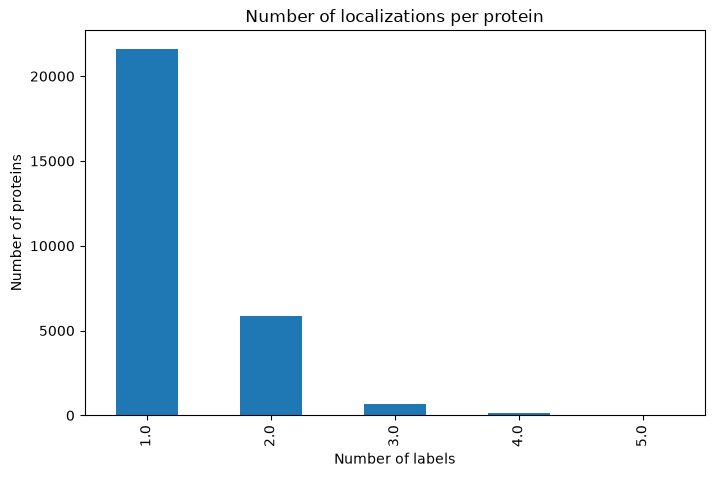

In [9]:
labels_per_protein.value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Number of localizations per protein")
plt.xlabel("Number of labels")
plt.ylabel("Number of proteins")
plt.show()

**Большинство белков имеют одну аннотацию локализации, реже - в двух, остальное распределение незначительное**

In [10]:
print(df['Partition'].value_counts().sort_values(ascending=False))

# Количество положительных меток в каждой группе
print(df.groupby("Partition")[target_columns].sum())

Partition
0    5963
2    5731
3    5696
4    5462
1    5451
Name: count, dtype: int64
           Cell membrane  Cytoplasm  Endoplasmic reticulum  Extracellular  \
Partition                                                                   
0                 1055.0     2119.0                  474.0          693.0   
1                  814.0     1996.0                  431.0          546.0   
2                  789.0     1928.0                  436.0          855.0   
3                  832.0     1996.0                  443.0          608.0   
4                  697.0     1831.0                  396.0          599.0   

           Golgi apparatus  Lysosome/Vacuole  Mitochondrion  Nucleus  \
Partition                                                              
0                    319.0             444.0          565.0   1871.0   
1                    244.0             278.0          491.0   1915.0   
2                    250.0             257.0          495.0   1931.0   
3             

**Количество белков в каждом фолде примерно одинаковое**

In [11]:
print("Total proteins:", len(y))

print("Total positive labels:", y.sum().sum())

print("Sum from labels_per_protein:", labels_per_protein.sum())

print("Average labels per protein:", labels_per_protein.mean())

Total proteins: 28303
Total positive labels: 35974.0
Sum from labels_per_protein: 35974.0
Average labels per protein: 1.2710313394339823


**В датасете содержится 28 303 белка и 35 974 положительные метки локализации. В среднем на один белок приходится 1,27 метки. Суммы совпадают, значит проверка данных пройдена успешно.**

# Preprocessing

In [20]:
# Длина каждой аминокислотной последовательности
df["sequence_length"] = df["Sequence"].str.len()

# Основная статистика
print(df["sequence_length"].describe())

# 99й процентиль
print("99th quantile:", df["sequence_length"].quantile(0.99))

# Самые короткие и длинные последовательности
print("Shortest:", df["sequence_length"].min())
print("Longest:", df["sequence_length"].max())

# Проверяем пропущенные последовательности
print("Missing sequences:", df["Sequence"].isna().sum())

# Проверяем повторяющиеся последовательности
print("Duplicate sequences:", df["Sequence"].duplicated().sum())

count    28303.000000
mean       556.901141
std        558.491431
min         40.000000
25%        261.000000
50%        433.000000
75%        681.000000
max      34350.000000
Name: sequence_length, dtype: float64
99th quantile: 2474.0
Shortest: 40
Longest: 34350
Missing sequences: 0
Duplicate sequences: 0


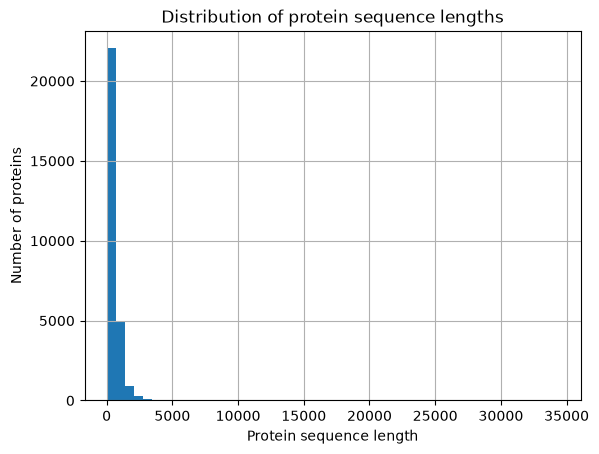

In [13]:
import matplotlib.pyplot as plt

df["sequence_length"].hist(bins=50)

plt.xlabel("Protein sequence length")
plt.ylabel("Number of proteins")
plt.title("Distribution of protein sequence lengths")
plt.show()

In [ ]:


all_sequences = "".join(df["Sequence"].dropna())

amino_acid_counts = Counter(all_sequences)

print(amino_acid_counts)

Counter({'L': 1509936, 'S': 1346622, 'E': 1100447, 'A': 1083977, 'G': 978632, 'V': 964858, 'K': 963106, 'P': 878412, 'T': 854026, 'R': 845306, 'D': 824731, 'I': 776299, 'Q': 705440, 'N': 677833, 'F': 607158, 'Y': 445161, 'H': 376869, 'M': 349019, 'C': 294619, 'W': 179392, 'U': 78, 'X': 51, 'B': 1})


In [37]:
all_sequences_df = pd.DataFrame(
    {'amino_acid': amino_acid_counts.keys(), 
    'count': amino_acid_counts.values()}
)

all_sequences_df.sort_values(by='count', ascending=False)

,amino_acid,count
7,L,1509936
4,S,1346622
9,E,1100447
1,A,1083977
2,G,978632
8,V,964858
15,K,963106
5,P,878412
16,T,854026
3,R,845306


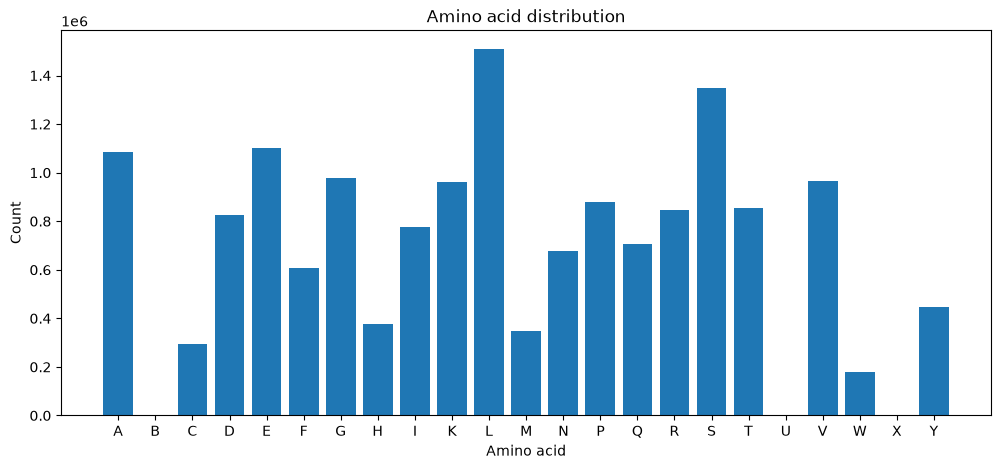

In [26]:
amino_acids = sorted(amino_acid_counts)

counts = [amino_acid_counts[aa] for aa in amino_acids]

plt.figure(figsize=(12, 5))
plt.bar(amino_acids, counts)

plt.xlabel("Amino acid")
plt.ylabel("Count")
plt.title("Amino acid distribution")

plt.show()

index	amino_acid	count
7	L	1509936
4	S	1346622
9	E	1100447
1	A	1083977
2	G	978632
8	V	964858
15	K	963106
5	P	878412
16	T	854026
3	R	845306
10	D	824731
14	I	776299
13	Q	705440
12	N	677833
17	F	607158
11	Y	445161
6	H	376869
0	M	349019
18	C	294619
19	W	179392
20	U	78
21	X	51
22	B	1